In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, r2_score, roc_auc_score
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

ROLL_NO = 'S24BCAU0161'
SEED = int(ROLL_NO[-3:])          # 161
os.makedirs('results', exist_ok=True); os.makedirs('figures', exist_ok=True)
R = {}                             # every headline number goes here -> results/summary.json
print('Seed =', SEED)

Seed = 161


In [2]:
URL = 'https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv'
LOCAL = 'data/compas-scores-two-years.csv'
if os.path.exists(LOCAL):
    raw = pd.read_csv(LOCAL)
else:
    raw = pd.read_csv(URL); os.makedirs('data', exist_ok=True); raw.to_csv(LOCAL, index=False)
raw = raw.loc[:, ~raw.columns.duplicated()]   # file repeats decile_score / priors_count
print(raw.shape)
R['n_raw'] = len(raw)

(7214, 53)


In [3]:
df = raw[(raw.days_b_screening_arrest <= 30) & (raw.days_b_screening_arrest >= -30) &
         (raw.is_recid != -1) & (raw.c_charge_degree != 'O') & (raw.score_text != 'N/A')].copy()
R['n_clean'] = len(df)
print('after filtering:', df.shape)

df['male']   = (df.sex == 'Male').astype(int)
df['felony'] = (df.c_charge_degree == 'F').astype(int)
df['race_grp'] = df.race.replace({'Asian': 'Other', 'Native American': 'Other'})
for r_, name in [('African-American', 'race_AA'), ('Hispanic', 'race_Hispanic'), ('Other', 'race_Other')]:
    df[name] = (df.race_grp == r_).astype(int)
df['jail_days'] = (pd.to_datetime(df.c_jail_out) - pd.to_datetime(df.c_jail_in)).dt.days.clip(lower=0)
df['log_jail_days'] = np.log1p(df.jail_days)

FEATURES = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count',
            'log_jail_days', 'male', 'felony', 'race_AA', 'race_Hispanic', 'race_Other']
CONT = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'log_jail_days']

miss = df[FEATURES + ['decile_score', 'two_year_recid']].isna().sum()
print('missing values in modelling columns:'); print(miss[miss > 0] if miss.sum() else 'none')
print('\nother columns with missing values:'); print(df.isna().sum()[df.isna().sum() > 0])
R['missing_other'] = {k: int(v) for k, v in df.isna().sum()[df.isna().sum() > 0].items()}
R['race_counts'] = df.race.value_counts().to_dict()
print(df.race_grp.value_counts())

after filtering: (6172, 53)
missing values in modelling columns:
none

other columns with missing values:
c_offense_date         784
c_arrest_date         5388
c_charge_desc            5
r_case_number         3182
r_charge_degree       3182
r_days_from_arrest    4175
r_offense_date        3182
r_charge_desc         3228
r_jail_in             4175
r_jail_out            4175
violent_recid         6172
vr_case_number        5480
vr_charge_degree      5480
vr_offense_date       5480
vr_charge_desc        5480
dtype: int64
race_grp
African-American    3175
Caucasian           2103
Hispanic             509
Other                385
Name: count, dtype: int64


In [4]:
train_idx, test_idx = train_test_split(df.index, test_size=0.30, random_state=SEED,
                                       stratify=df.two_year_recid)
# winsorise long-tailed counts at the TRAIN 99th percentile, applied to all rows
CAPS = {c: float(df.loc[train_idx, c].quantile(0.99)) for c in
        ['priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']}
CAPS = {c: max(v, 1.0) for c, v in CAPS.items()}   # never cap a count below 1
for c, v in CAPS.items():
    R[f'n_capped_{c}'] = int((df[c] > v).sum())
    df[c] = df[c].clip(upper=v)
print('winsorisation caps:', CAPS, {k: v for k, v in R.items() if k.startswith('n_capped')})
R['caps'] = CAPS

train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()
scaler = StandardScaler().fit(train[CONT])
def design(d):
    X = d[FEATURES].astype(float).copy(); X[CONT] = scaler.transform(d[CONT]); return X
Xtr, Xte = design(train), design(test)
R.update(n_train=len(train), n_test=len(test), base_rate_test=float(test.two_year_recid.mean()))
print(len(train), len(test), 'test base rate', round(test.two_year_recid.mean(), 4))
df[FEATURES + ['decile_score', 'two_year_recid']].describe().T.round(3)

winsorisation caps: {'priors_count': 22.0, 'juv_fel_count': 2.0, 'juv_misd_count': 2.0, 'juv_other_count': 2.0} {'n_capped_priors_count': 56, 'n_capped_juv_fel_count': 32, 'n_capped_juv_misd_count': 44, 'n_capped_juv_other_count': 50}
4320 1852 test base rate 0.4552


,count,mean,std,min,25%,50%,75%,max
age,6172.0,34.535,11.731,18.0,25.0,31.000,42.000,96.000
priors_count,6172.0,3.208,4.556,0.0,0.0,1.000,4.000,22.000
juv_fel_count,6172.0,0.045,0.255,0.0,0.0,0.000,0.000,2.000
juv_misd_count,6172.0,0.074,0.320,0.0,0.0,0.000,0.000,2.000
juv_other_count,6172.0,0.097,0.362,0.0,0.0,0.000,0.000,2.000
log_jail_days,6172.0,1.220,1.455,0.0,0.0,0.693,1.792,6.685
male,6172.0,0.810,0.393,0.0,1.0,1.000,1.000,1.000
felony,6172.0,0.643,0.479,0.0,0.0,1.000,1.000,1.000
race_AA,6172.0,0.514,0.500,0.0,0.0,1.000,1.000,1.000
race_Hispanic,6172.0,0.082,0.275,0.0,0.0,0.000,0.000,1.000


In [5]:
mA = LinearRegression().fit(Xtr, train.decile_score)
mB = LogisticRegression(penalty=None, max_iter=5000).fit(Xtr, train.two_year_recid)

predA = mA.predict(Xte)
probB = mB.predict_proba(Xte)[:, 1]
medA = float(np.median(predA))
hiA = (predA >= medA).astype(int)
hiB = (probB >= 0.5).astype(int)

coefs = pd.DataFrame({'ModelA_OLS_decile': mA.coef_, 'ModelB_logit': mB.coef_[0]}, index=FEATURES)
coefs.loc['intercept'] = [mA.intercept_, mB.intercept_[0]]
coefs.round(4).to_csv('results/part1_coefficients.csv'); print(coefs.round(4))

R['p1'] = dict(
    A_r2_test=float(r2_score(test.decile_score, predA)),
    A_pred_min=float(predA.min()), A_pred_max=float(predA.max()), A_median=medA,
    A_median_as_decile_pctile=float((test.decile_score <= medA).mean()),
    B_acc_test=float(accuracy_score(test.two_year_recid, hiB)),
    B_auc_test=float(roc_auc_score(test.two_year_recid, probB)),
    B_median_prob=float(np.median(probB)),
    A_flag_rate=float(hiA.mean()), B_flag_rate=float(hiB.mean()),
    A_acc_vs_recid=float(accuracy_score(test.two_year_recid, hiA)),
    A_auc_vs_recid=float(roc_auc_score(test.two_year_recid, predA)),
    # the logistic probability at which B would flag exactly as many people as A
    B_prob_at_A_rate=float(np.quantile(probB, 1 - hiA.mean())),
    corr_A_B=float(np.corrcoef(predA, probB)[0, 1]),
    coefs=coefs.round(5).to_dict(),
)
cm = confusion_matrix(hiA, hiB)   # rows = Model A, cols = Model B
cm_df = pd.DataFrame(cm, index=['A: low', 'A: high'], columns=['B: low', 'B: high'])
mism = int(cm[0, 1] + cm[1, 0])
R['p1'].update(cm=cm.tolist(), mismatch=mism, mismatch_pct=mism / len(test),
               A_high_B_low=int(cm[1, 0]), A_low_B_high=int(cm[0, 1]))
cm_df.to_csv('results/part1_confusion.csv')
print(cm_df); print(json.dumps({k: v for k, v in R['p1'].items() if k != 'coefs'}, indent=1))

                 ModelA_OLS_decile  ModelB_logit
age                        -1.1806       -0.5232
priors_count                1.1392        0.7036
juv_fel_count               0.1797        0.0033
juv_misd_count              0.0806        0.0328
juv_other_count             0.1198        0.0727
log_jail_days               0.4898        0.2195
male                       -0.1136        0.3657
felony                      0.3705        0.1866
race_AA                     0.4762        0.0603
race_Hispanic              -0.4645       -0.2283
race_Other                 -0.7471       -0.1886
intercept                   4.1466       -0.6021
         B: low  B: high
A: low      918        8
A: high     231      695
{
 "A_r2_test": 0.4642537934311103,
 "A_pred_min": -3.0847889809464446,
 "A_pred_max": 12.406218810938686,
 "A_median": 4.433746745780767,
 "A_median_as_decile_pctile": 0.5755939524838013,
 "B_acc_test": 0.673866090712743,
 "B_auc_test": 0.7245578641573408,
 "B_median_prob": 0.4391813922

                   n     age  priors  pct_AA  pct_male  recid_rate  mean_decile  mean_predA  mean_probB
agree                                                                                                  
A high / B low   231  26.017   1.030   0.753     0.636       0.416        4.996       4.825       0.445
A low / B high     8  51.875  10.500   0.375     1.000       0.500        4.500       4.115       0.524
agree           1613  35.790   3.485   0.482     0.854       0.461        4.237       4.380       0.457


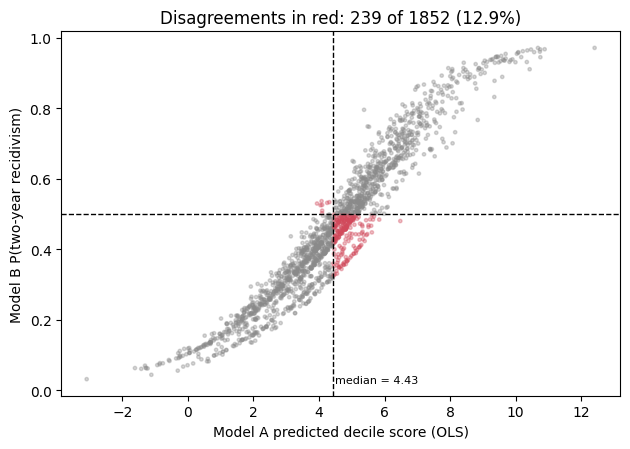

In [6]:
# who are the disagreements?
test['predA'], test['probB'], test['hiA'], test['hiB'] = predA, probB, hiA, hiB
test['agree'] = np.where(hiA == hiB, 'agree', np.where(hiA == 1, 'A high / B low', 'A low / B high'))
prof = test.groupby('agree').agg(n=('age', 'size'), age=('age', 'mean'), priors=('priors_count', 'mean'),
        pct_AA=('race_AA', 'mean'), pct_male=('male', 'mean'), recid_rate=('two_year_recid', 'mean'),
        mean_decile=('decile_score', 'mean'), mean_predA=('predA', 'mean'), mean_probB=('probB', 'mean'))
prof.round(3).to_csv('results/part1_mismatch_profile.csv'); print(prof.round(3))
R['p1']['mismatch_profile'] = prof.round(4).reset_index().to_dict('records')

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.scatter(predA, probB, s=6, alpha=.35, c=np.where(hiA == hiB, '#8a8a8a', '#d1495b'))
ax.axvline(medA, ls='--', c='k', lw=1); ax.axhline(.5, ls='--', c='k', lw=1)
ax.set_xlabel('Model A predicted decile score (OLS)'); ax.set_ylabel('Model B P(two-year recidivism)')
ax.set_title(f'Disagreements in red: {mism} of {len(test)} ({mism/len(test):.1%})')
ax.text(medA + .05, .02, f'median = {medA:.2f}', fontsize=8)
plt.tight_layout(); plt.savefig('figures/part1_scatter.png', dpi=160); plt.show()

In [7]:
SIMP_X = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count',
          'log_jail_days', 'felony', 'race_AA', 'race_Hispanic', 'race_Other']
def logit(d, cols, y='two_year_recid'):
    return sm.Logit(d[y], sm.add_constant(d[cols].astype(float))).fit(disp=0)

groups = {'Full': df, 'Subgroup A: Male': df[df.male == 1], 'Subgroup B: Female': df[df.male == 0]}
fits = {k: logit(v, SIMP_X) for k, v in groups.items()}
rows = []
for k, m in fits.items():
    ci = m.conf_int()
    for v in ['race_AA', 'juv_fel_count', 'priors_count', 'age']:
        rows.append(dict(model=k, n=int(m.nobs), predictor=v, coef=m.params[v], ci_low=ci.loc[v, 0],
                         ci_high=ci.loc[v, 1], p=m.pvalues[v], odds_ratio=np.exp(m.params[v])))
simp = pd.DataFrame(rows); simp.round(4).to_csv('results/part2_1_simpson.csv', index=False)
print(simp.round(4).to_string(index=False))

# raw (unadjusted) recidivism rates, AA vs Caucasian, by sex
raw_rates = df[df.race_grp.isin(['African-American', 'Caucasian'])].pivot_table(
    index='sex', columns='race_grp', values='two_year_recid', aggfunc=['mean', 'size'])
print(raw_rates.round(3))

             model    n     predictor    coef  ci_low  ci_high      p  odds_ratio
              Full 6172       race_AA  0.0688 -0.0558   0.1934 0.2789      1.0713
              Full 6172 juv_fel_count  0.0295 -0.2145   0.2735 0.8126      1.0300
              Full 6172  priors_count  0.1533  0.1370   0.1696 0.0000      1.1657
              Full 6172           age -0.0427 -0.0482  -0.0372 0.0000      0.9582
  Subgroup A: Male 4997       race_AA  0.1481  0.0090   0.2873 0.0369      1.1596
  Subgroup A: Male 4997 juv_fel_count  0.0372 -0.2142   0.2887 0.7717      1.0379
  Subgroup A: Male 4997  priors_count  0.1434  0.1262   0.1607 0.0000      1.1542
  Subgroup A: Male 4997           age -0.0443 -0.0504  -0.0383 0.0000      0.9566
Subgroup B: Female 1175       race_AA -0.2963 -0.5851  -0.0076 0.0442      0.7435
Subgroup B: Female 1175 juv_fel_count -0.2943 -1.3987   0.8100 0.6014      0.7450
Subgroup B: Female 1175  priors_count  0.2081  0.1565   0.2598 0.0000      1.2314
Subgroup B: Fema

                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.3763      0.140      2.696      0.007       0.103       0.650
age                -0.0429      0.003    -15.276      0.000      -0.048      -0.037
priors_count        0.1504      0.008     18.032      0.000       0.134       0.167
juv_fel_count       0.0073      0.125      0.059      0.953      -0.237       0.251
juv_misd_count      0.0579      0.105      0.553      0.580      -0.147       0.263
juv_other_count     0.3353      0.086      3.918      0.000       0.168       0.503
log_jail_days       0.1418      0.020      7.044      0.000       0.102       0.181
felony              0.1779      0.060      2.980      0.003       0.061       0.295
race_AA             0.1309      0.070      1.878      0.060      -0.006       0.267
race_Hispanic      -0.1617      0.110     -1.473      0.141      -0.377     

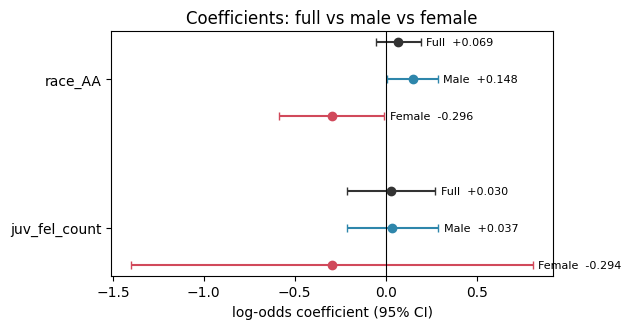

In [ ]:
d2 = df.copy(); d2['AA_x_female'] = d2.race_AA * (1 - d2.male)
mi = logit(d2, SIMP_X + ['male', 'AA_x_female'])
ci = mi.conf_int()
cells_ = {f'{s}|{r}': df[(df.sex == s) & (df.race_grp == r)] for s in ['Male', 'Female'] for r in ['African-American', 'Caucasian']}
R['p2_1'] = dict(
    rows=simp.round(5).to_dict('records'),
    interaction_coef=float(mi.params['AA_x_female']), interaction_p=float(mi.pvalues['AA_x_female']),
    interaction_ci=[float(ci.loc['AA_x_female', 0]), float(ci.loc['AA_x_female', 1])],
    int_model_raceAA=float(mi.params['race_AA']), int_model_raceAA_p=float(mi.pvalues['race_AA']),
    cell_n={k: len(v) for k, v in cells_.items()},
    raw_rates={k: float(v.two_year_recid.mean()) for k, v in cells_.items()},
    mean_priors={k: float(v.priors_count.mean()) for k, v in cells_.items()},
    mean_age={k: float(v.age.mean()) for k, v in cells_.items()},
    share_female=float((df.male == 0).mean()),
)
print(mi.summary().tables[1]); print(json.dumps({k: v for k, v in R['p2_1'].items() if k != 'rows'}, indent=1))

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for i, v in enumerate(['race_AA', 'juv_fel_count']):
    sub = simp[simp.predictor == v]
    for j, (_, r) in enumerate(sub.iterrows()):
        y = i * 4 + j
        ax.errorbar(r.coef, y, xerr=[[r.coef - r.ci_low], [r.ci_high - r.coef]], fmt='o',
                    c=['#333333', '#2e86ab', '#d1495b'][j], capsize=3)
        ax.text(r.ci_high + .03, y, f"{r.model.split(':')[-1].strip()}  {r.coef:+.3f}", va='center', fontsize=8)
ax.axvline(0, c='k', lw=.8); ax.set_yticks([1, 5]); ax.set_yticklabels(['race_AA', 'juv_fel_count'])
ax.invert_yaxis(); ax.set_xlabel('log-odds coefficient (95% CI)'); ax.set_title('Coefficients: full vs male vs female')
plt.tight_layout(); plt.savefig('figures/part2_1_forest.png', dpi=160); plt.show()

In [9]:
OVB_X = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count',
         'log_jail_days', 'male', 'felony', 'race_AA', 'race_Hispanic', 'race_Other']
full_m = logit(df, OVB_X)
red_m = logit(df, [c for c in OVB_X if c != 'priors_count'])
ovb = pd.DataFrame({'full_coef': full_m.params, 'reduced_coef': red_m.params,
                    'full_p': full_m.pvalues, 'reduced_p': red_m.pvalues}).drop(['const', 'priors_count'])
ovb['abs_change'] = ovb.reduced_coef - ovb.full_coef
ovb['pct_change'] = 100 * ovb.abs_change / ovb.full_coef.abs()
ovb = ovb.reindex(ovb['pct_change'].abs().sort_values(ascending=False).index)
ovb.round(4).to_csv('results/part2_2_ovb.csv'); print(ovb.round(4))
# why priors is a confounder: it correlates with the other predictors AND with the outcome
corr = df[OVB_X + ['two_year_recid']].corr()['priors_count'].drop('priors_count')
print('\ncorrelation of priors_count with others:\n', corr.round(3))
R['p2_2'] = dict(table=ovb.round(5).reset_index().rename(columns={'index': 'predictor'}).to_dict('records'),
                 priors_full_coef=float(full_m.params['priors_count']), corr_with_priors=corr.round(4).to_dict(),
                 aic_full=float(full_m.aic), aic_reduced=float(red_m.aic),
                 pseudo_r2_full=float(full_m.prsquared), pseudo_r2_reduced=float(red_m.prsquared),
                 mean_priors_AA=float(df[df.race_AA == 1].priors_count.mean()),
                 mean_priors_cauc=float(df[df.race_grp == 'Caucasian'].priors_count.mean()))

                 full_coef  reduced_coef  full_p  reduced_p  abs_change  pct_change
juv_fel_count       0.0119        0.4354  0.9239     0.0003      0.4235   3565.8143
juv_misd_count      0.0599        0.4778  0.5667     0.0000      0.4179    697.1123
race_AA             0.0602        0.2875  0.3447     0.0000      0.2273    377.6755
felony              0.1740        0.2932  0.0035     0.0000      0.1192     68.5430
log_jail_days       0.1419        0.2142  0.0000     0.0000      0.0723     50.9397
juv_other_count     0.3415        0.4650  0.0001     0.0000      0.1234     36.1338
age                -0.0428       -0.0277  0.0000     0.0000      0.0151     35.3430
male                0.3043        0.3944  0.0000     0.0000      0.0901     29.6110
race_Other         -0.1815       -0.2183  0.1399     0.0694     -0.0368    -20.2820
race_Hispanic      -0.1741       -0.1667  0.1134     0.1173      0.0073      4.2052

correlation of priors_count with others:
 age                0.117
juv_fel_

In [10]:
test['y'] = test.two_year_recid
conf_fp = test[(test.probB >= .75) & (test.y == 0)]
conf_fn = test[(test.probB <= .25) & (test.y == 1)]
wrong = pd.concat([conf_fp.assign(kind='FP (P>=0.75, y=0)'), conf_fn.assign(kind='FN (P<=0.25, y=1)')])
print('confident FP:', len(conf_fp), ' confident FN:', len(conf_fn), ' total:', len(wrong),
      f'({len(wrong)/len(test):.2%} of test set)')
adv = wrong.sample(n=min(50, len(wrong)), random_state=SEED)
adv.drop(columns=['name', 'first', 'last'], errors='ignore').to_csv('results/part2_3_adversarial_50.csv')

def profile(d):
    return pd.Series({'n': len(d), 'mean age': d.age.mean(), '% age <25': (d.age < 25).mean() * 100,
        '% age >45': (d.age > 45).mean() * 100, '% male': d.male.mean() * 100,
        '% African-American': d.race_AA.mean() * 100, '% Caucasian': (d.race_grp == 'Caucasian').mean() * 100,
        '% felony charge': d.felony.mean() * 100, 'mean priors': d.priors_count.mean(),
        '% priors = 0': (d.priors_count == 0).mean() * 100, '% priors >= 5': (d.priors_count >= 5).mean() * 100,
        'mean P(recid)': d.probB.mean(), 'actual recid %': d.y.mean() * 100})
comp = pd.DataFrame({'Full test set': profile(test), '50 adversarial rows': profile(adv),
                     'of which FP': profile(adv[adv.kind.str.startswith('FP')]),
                     'of which FN': profile(adv[adv.kind.str.startswith('FN')])})
comp.round(2).to_csv('results/part2_3_profile.csv'); print(comp.round(2))

confident FP: 37  confident FN: 58  total: 95 (5.13% of test set)
                    Full test set  50 adversarial rows  of which FP  of which FN
n                         1852.00                50.00        15.00        35.00
mean age                    34.64                43.70        34.20        47.77
% age <25                   20.68                 0.00         0.00         0.00
% age >45                   20.09                46.00         6.67        62.86
% male                      82.72                66.00       100.00        51.43
% African-American          51.51                34.00        60.00        22.86
% Caucasian                 33.42                34.00        26.67        37.14
% felony charge             64.04                46.00        73.33        34.29
mean priors                  3.21                 4.74        13.93         0.80
% priors = 0                34.13                36.00         0.00        51.43
% priors >= 5               23.76          

{
 "n_conf_fp": 37,
 "n_conf_fn": 58,
 "n_wrong": 95,
 "pct_wrong": 0.05129589632829374,
 "n_sample": 50,
 "n_fp_sample": 15,
 "n_fn_sample": 35,
 "fp_priors5_pct": 1.0,
 "fp_age_lt25_pct": 0.0,
 "fp_priors5_or_lt25": 1.0,
 "fn_priors01_pct": 0.8285714285714286,
 "fn_age30_pct": 0.9714285714285714,
 "fn_priors01_and_30": 0.8,
 "fn_misd_pct": 0.6571428571428571,
 "shared_trait_pct": 0.86
}
               n  mean_pred  actual
probB                              
(0.0, 0.25]  294      0.173   0.197
(0.25, 0.5]  855      0.382   0.367
(0.5, 0.75]  532      0.603   0.633
(0.75, 1.0]  171      0.853   0.784
with age*priors + priors^2: 106 confident errors; AUC 0.7279 vs 0.7246


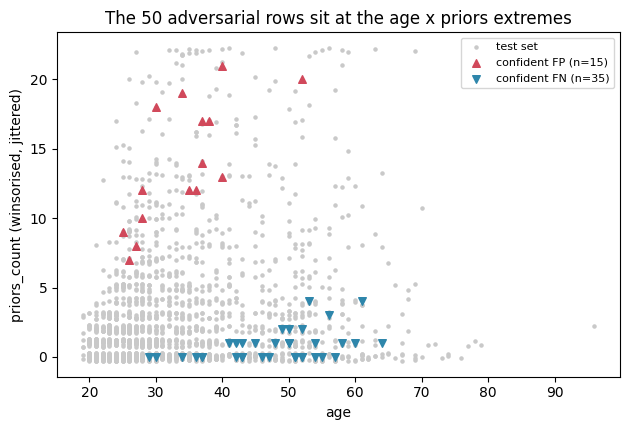

In [ ]:
fp, fn = adv[adv.kind.str.startswith('FP')], adv[adv.kind.str.startswith('FN')]
R['p2_3'] = dict(n_conf_fp=len(conf_fp), n_conf_fn=len(conf_fn), n_wrong=len(wrong),
    pct_wrong=len(wrong) / len(test), n_sample=len(adv), n_fp_sample=len(fp), n_fn_sample=len(fn),
    profile=comp.round(3).to_dict(),
    fp_priors5_pct=float((fp.priors_count >= 5).mean()), fp_age_lt25_pct=float((fp.age < 25).mean()),
    fp_priors5_or_lt25=float(((fp.priors_count >= 5) | (fp.age < 25)).mean()),
    fn_priors01_pct=float((fn.priors_count <= 1).mean()), fn_age30_pct=float((fn.age >= 30).mean()),
    fn_priors01_and_30=float(((fn.priors_count <= 1) & (fn.age >= 30)).mean()),
    fn_misd_pct=float((fn.felony == 0).mean()))
R['p2_3']['shared_trait_pct'] = float((((fp.priors_count >= 5) | (fp.age < 25)).sum() +
                                       ((fn.priors_count <= 1) & (fn.age >= 30)).sum()) / len(adv))
print(json.dumps({k: v for k, v in R['p2_3'].items() if k != 'profile'}, indent=1))

bins = pd.cut(test.probB, [0, .25, .5, .75, 1])
calib = test.groupby(bins).agg(n=('y', 'size'), mean_pred=('probB', 'mean'), actual=('y', 'mean'))
print(calib.round(3)); R['p2_3']['calibration'] = calib.round(4).reset_index().astype(str).to_dict('records')

tr2, te2 = Xtr.copy(), Xte.copy()
for X_ in (tr2, te2):
    X_['age_x_priors'] = X_.age * X_.priors_count; X_['priors_sq'] = X_.priors_count ** 2
mB2 = LogisticRegression(penalty=None, max_iter=5000).fit(tr2, train.two_year_recid)
p2 = mB2.predict_proba(te2)[:, 1]
n_wrong2 = int((((p2 >= .75) & (test.y == 0)) | ((p2 <= .25) & (test.y == 1))).sum())
R['p2_3'].update(n_wrong_with_interactions=n_wrong2, auc_with_interactions=float(roc_auc_score(test.y, p2)),
                 coef_age_x_priors=float(mB2.coef_[0][list(tr2.columns).index('age_x_priors')]),
                 coef_priors_sq=float(mB2.coef_[0][list(tr2.columns).index('priors_sq')]),
                 sd_age=float(scaler.scale_[0]), sd_priors=float(scaler.scale_[1]))
print('with age*priors + priors^2:', n_wrong2, 'confident errors; AUC', round(roc_auc_score(test.y, p2), 4),
      'vs', round(R['p1']['B_auc_test'], 4))

fig, ax = plt.subplots(figsize=(6.4, 4.4))
jit = np.random.default_rng(SEED).uniform(-.3, .3, len(test))
ax.scatter(test.age, test.priors_count + jit, s=5, c='#c9c9c9', label='test set')
ax.scatter(fp.age, fp.priors_count, s=30, c='#d1495b', marker='^', label=f'confident FP (n={len(fp)})')
ax.scatter(fn.age, fn.priors_count, s=30, c='#2e86ab', marker='v', label=f'confident FN (n={len(fn)})')
ax.set_xlabel('age'); ax.set_ylabel('priors_count (winsorised, jittered)'); ax.legend(fontsize=8)
ax.set_title('The 50 adversarial rows sit at the age x priors extremes')
plt.tight_layout(); plt.savefig('figures/part2_3_adversarial.png', dpi=160); plt.show()

In [12]:
gA = test[test.race_grp == 'Caucasian']; gB = test[test.race_grp == 'African-American']
def rates(g, t):
    yhat = (g.probB >= t).astype(int); y = g.y
    tpr = yhat[y == 1].mean(); fpr = yhat[y == 0].mean()
    ppv = y[yhat == 1].mean() if yhat.sum() else np.nan
    return yhat.mean(), tpr, fpr, ppv
rows = []
for t in np.round(np.arange(.05, 1.0, .1), 2):
    sa, ta, fa, pa = rates(gA, t); sb, tb, fb, pb = rates(gB, t)
    tpr_r = ta / tb if tb else np.nan; fpr_r = fa / fb if fb else np.nan
    rows.append(dict(t=t, sel_A=sa, sel_B=sb, TPR_A=ta, TPR_B=tb, FPR_A=fa, FPR_B=fb, PPV_A=pa, PPV_B=pb,
        DP=sa / sb if sb else np.nan, TPR_ratio=tpr_r, FPR_ratio=fpr_r,
        EO=np.nanmin([tpr_r, fpr_r]) if not (np.isnan(tpr_r) and np.isnan(fpr_r)) else np.nan,
        PP=pa / pb if (pb and not np.isnan(pa) and not np.isnan(pb)) else np.nan,
        acc=accuracy_score(test.y, (test.probB >= t)),
        acc_A=accuracy_score(gA.y, (gA.probB >= t)), acc_B=accuracy_score(gB.y, (gB.probB >= t)),
        n_flag_A=int((gA.probB >= t).sum()), n_flag_B=int((gB.probB >= t).sum())))
fair = pd.DataFrame(rows); fair.round(4).to_csv('results/part2_4_fairness.csv', index=False)
R['p2_4'] = dict(table=fair.round(5).to_dict('records'), n_A=len(gA), n_B=len(gB),
                 base_A=float(gA.y.mean()), base_B=float(gB.y.mean()),
                 meanP_A=float(gA.probB.mean()), meanP_B=float(gB.probB.mean()))
print('n_A', len(gA), 'n_B', len(gB), 'base rates', round(gA.y.mean(), 3), round(gB.y.mean(), 3))
fair[['t', 'DP', 'EO', 'PP', 'TPR_ratio', 'FPR_ratio', 'acc', 'sel_A', 'sel_B', 'FPR_A', 'FPR_B']].round(3)

n_A 619 n_B 954 base rates 0.391 0.521


,t,DP,EO,PP,TPR_ratio,FPR_ratio,acc,sel_A,sel_B,FPR_A,FPR_B
0,0.05,1.000,1.000,0.750,1.000,1.000,0.455,1.000,1.000,1.000,1.000
1,0.15,0.923,0.893,0.793,0.975,0.893,0.491,0.910,0.985,0.870,0.974
2,0.25,0.804,0.740,0.855,0.917,0.740,0.551,0.754,0.938,0.666,0.899
3,0.35,0.689,0.638,0.875,0.803,0.638,0.625,0.564,0.819,0.451,0.707
4,0.45,0.550,0.552,0.849,0.623,0.552,0.664,0.347,0.631,0.257,0.466
5,0.55,0.420,0.359,0.966,0.541,0.359,0.667,0.171,0.408,0.085,0.236
6,0.65,0.300,0.205,1.044,0.417,0.205,0.630,0.081,0.269,0.029,0.142
7,0.75,0.279,0.314,0.895,0.333,0.314,0.597,0.040,0.145,0.019,0.059
8,0.85,0.169,0.193,0.855,0.193,0.269,0.577,0.013,0.077,0.005,0.020
9,0.95,0.128,0.000,1.091,0.187,0.000,0.551,0.002,0.013,0.000,0.002


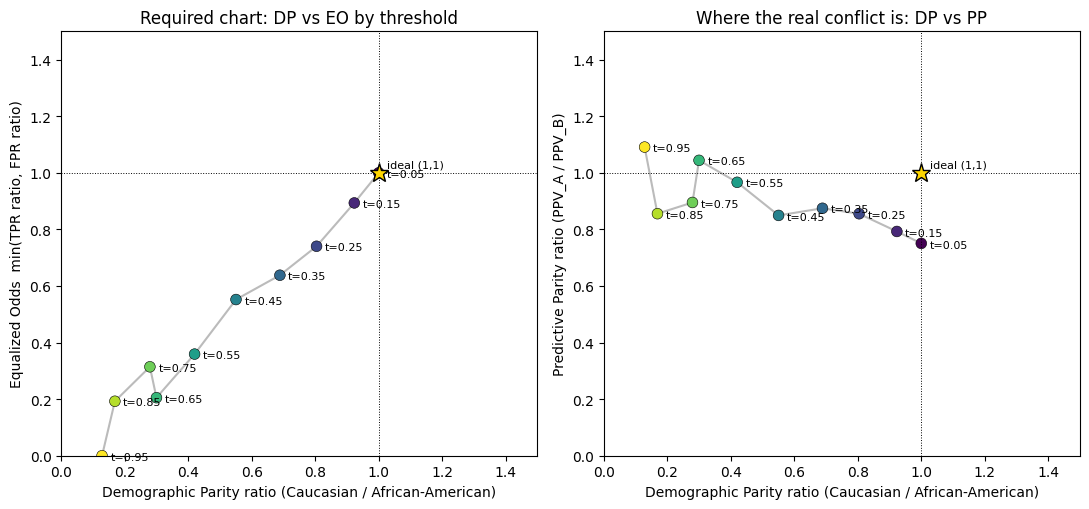

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, ycol, ylab in [(axes[0], 'EO', 'Equalized Odds  min(TPR ratio, FPR ratio)'),
                       (axes[1], 'PP', 'Predictive Parity ratio (PPV_A / PPV_B)')]:
    f = fair.dropna(subset=['DP', ycol])
    ax.plot(f.DP, f[ycol], '-', c='#bbbbbb', zorder=1)
    ax.scatter(f.DP, f[ycol], c=f.t, cmap='viridis', s=60, zorder=2, edgecolor='k', lw=.4)
    for _, r in f.iterrows():
        ax.annotate(f't={r.t:.2f}', (r.DP, r[ycol]), textcoords='offset points', xytext=(6, -3), fontsize=8)
    ax.plot(1, 1, marker='*', ms=14, c='gold', mec='k', zorder=3)
    ax.annotate('ideal (1,1)', (1, 1), xytext=(6, 4), textcoords='offset points', fontsize=8)
    ax.axvline(1, ls=':', c='k', lw=.7); ax.axhline(1, ls=':', c='k', lw=.7)
    ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5)
    ax.set_xlabel('Demographic Parity ratio (Caucasian / African-American)'); ax.set_ylabel(ylab)
axes[0].set_title('Required chart: DP vs EO by threshold'); axes[1].set_title('Where the real conflict is: DP vs PP')
plt.tight_layout(); plt.savefig('figures/part2_4_tradeoff.png', dpi=160); plt.show()

In [ ]:
def tradeoff(a, b):
    z = 100 * (b.DP - a.DP) / a.DP                     
    w = 100 * (a.EO - b.EO) / a.EO                     
    pp_gap_a, pp_gap_b = abs(a.PP - 1), abs(b.PP - 1)
    return dict(t_from=float(a.t), t_to=float(b.t), DP_from=float(a.DP), DP_to=float(b.DP),
                EO_from=float(a.EO), EO_to=float(b.EO), DP_gain_pct=float(z), EO_loss_pct=float(w),
                cost_EO=float(w / z) if z else np.nan,
                PP_from=float(a.PP), PP_to=float(b.PP),
                PP_loss_pct=float(100 * (pp_gap_b - pp_gap_a) / (1 - pp_gap_a)), 
                cost_PP=float(100 * (pp_gap_b - pp_gap_a) / (1 - pp_gap_a) / z) if z else np.nan,
                acc_from=float(a.acc), acc_to=float(b.acc))
steps = pd.DataFrame([tradeoff(fair.iloc[i + 1], fair.iloc[i]) for i in range(len(fair) - 1)])  
steps.round(4).to_csv('results/part2_4_tradeoff_steps.csv', index=False)
print(steps.round(3).to_string(index=False))
row = lambda t: fair.loc[(fair.t - t).abs().idxmin()]
headline = tradeoff(row(.55), row(.35))    
R['p2_4'].update(steps=steps.round(5).to_dict('records'), headline=headline,
                 best_dp_t=float(fair.loc[(fair.DP - 1).abs().idxmin()].t), best_eo_t=float(fair.loc[(fair.EO - 1).abs().idxmin()].t),
                 best_pp_t=float(fair.loc[(fair.PP - 1).abs().idxmin()].t), best_acc_t=float(fair.loc[fair.acc.idxmax()].t))
print(json.dumps({k: R['p2_4'][k] for k in ['headline', 'best_dp_t', 'best_eo_t', 'best_pp_t', 'best_acc_t']}, indent=1))

 t_from  t_to  DP_from  DP_to  EO_from  EO_to  DP_gain_pct  EO_loss_pct  cost_EO  PP_from  PP_to  PP_loss_pct  cost_PP  acc_from  acc_to
   0.15  0.05    0.923  1.000    0.893  1.000        8.333      -11.921   -1.431    0.793  0.750        5.325    0.639     0.491   0.455
   0.25  0.15    0.804  0.923    0.740  0.893       14.785      -20.693   -1.400    0.855  0.793        7.324    0.495     0.551   0.491
   0.35  0.25    0.689  0.804    0.638  0.740       16.767      -16.034   -0.956    0.875  0.855        2.208    0.132     0.625   0.551
   0.45  0.35    0.550  0.689    0.552  0.638       25.122      -15.572   -0.620    0.849  0.875       -2.973   -0.118     0.664   0.625
   0.55  0.45    0.420  0.550    0.359  0.552       31.065      -53.697   -1.729    0.966  0.849       12.114    0.390     0.667   0.664
   0.65  0.55    0.300  0.420    0.205  0.359       40.062      -75.084   -1.874    1.044  0.966       -1.097   -0.027     0.630   0.667
   0.75  0.65    0.279  0.300    0.314  0

In [ ]:
scen = []
for t in [0.35, 0.45, 0.55]:
    for name, g in [('Caucasian', gA), ('African-American', gB)]:
        neg = g[g.y == 0]
        scen.append(dict(t=t, group=name, n_non_reoffenders=len(neg), n_wrongly_flagged=int((neg.probB >= t).sum()),
                         FPR=float((neg.probB >= t).mean()), PPV=float(g[g.probB >= t].y.mean())))
scen = pd.DataFrame(scen); scen.round(4).to_csv('results/q6_scenario.csv', index=False); print(scen.round(3))
R['q6'] = scen.round(5).to_dict('records')

nA, nB_ = int(hiA.sum()), int(hiB.sum())
R['p1'].update(n_flag_A=nA, n_flag_B=nB_, min_possible_mismatch=abs(nA - nB_),
               B_flag_pctile_of_0_5=float((probB < 0.5).mean()))
print('A flags', nA, 'B flags', nB_, '-> at least', abs(nA - nB_), 'mismatches forced by flag counts alone')

def e_value(rr):
    rr = rr if rr >= 1 else 1 / rr
    return rr + np.sqrt(rr * (rr - 1))
male_row = simp[(simp.model == 'Subgroup A: Male') & (simp.predictor == 'race_AA')].iloc[0]
rr_pt, rr_lo = np.sqrt(np.exp(male_row.coef)), np.sqrt(np.exp(male_row.ci_low))
R['q4'] = dict(male_raceAA_OR=float(np.exp(male_row.coef)), approx_RR=float(rr_pt),
               e_value_point=float(e_value(rr_pt)), e_value_ci=float(e_value(rr_lo)) if rr_lo > 1 else 1.0)
print(R['q4'])

      t             group  n_non_reoffenders  n_wrongly_flagged    FPR    PPV
0  0.35         Caucasian                377                170  0.451  0.513
1  0.35  African-American                457                323  0.707  0.586
2  0.45         Caucasian                377                 97  0.257  0.549
3  0.45  African-American                457                213  0.466  0.646
4  0.55         Caucasian                377                 32  0.085  0.698
5  0.55  African-American                457                108  0.236  0.722
A flags 926 B flags 703 -> at least 223 mismatches forced by flag counts alone
{'male_raceAA_OR': 1.1596497002159325, 'approx_RR': 1.076870326555585, 'e_value_point': 1.3645843749792714, 'e_value_ci': 1.0716991703022214}


In [16]:
with open('results/summary.json', 'w') as fh:
    json.dump(R, fh, indent=1, default=float)
print('saved results/summary.json')

saved results/summary.json
